# Gestión de Inventarios — Clase Práctica
### Investigación Operativa · Universidad de San Andrés

Este notebook cubre el modelo EOQ y sus extensiones, desde los casos determinísticos hasta la simulación Monte Carlo con demanda estocástica.

**Estructura:**
1. EOQ Clásico — modelo base
2. Punto de Reorden (lead time)
3. EOQ con Faltantes Permitidos
4. Descuentos por Cantidad
5. Análisis de Sensibilidad
6. Demanda Estocástica — Montecarlo
7. Ejercicio Integrador (Thinkpad)


## 0. Librerías e imports

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats

# Estilo visual consistente
plt.rcParams.update({
    'figure.facecolor': '#FAFAFA',
    'axes.facecolor': '#F5F5F5',
    'axes.grid': True,
    'grid.alpha': 0.4,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 12,
})

print("Librerías cargadas")


Librerías cargadas


---
## 1. EOQ Clásico (sin faltantes, sin lead time)

El modelo EOQ minimiza el **costo total** de inventario:

$$CT(Q) = \underbrace{\frac{KD}{Q}}_{\text{costo de ordenar}} + \underbrace{\frac{hQ}{2}}_{\text{costo de mantener}}$$

La cantidad óptima es:
$$Q^* = \sqrt{\frac{2KD}{h}}$$

### Caso: Lenovo Thinkpad
Un local vende 12.000 computadoras por año. Costo por orden: \$500. Costo de mantener: \$10/unidad/mes.


  Cantidad óptima Q*    :   316.23  unidades
  Tiempo entre pedidos  :     9.62  días
  Pedidos por año N*    :     37.9  pedidos
  Costo total anual CT  : 37,947.33  $


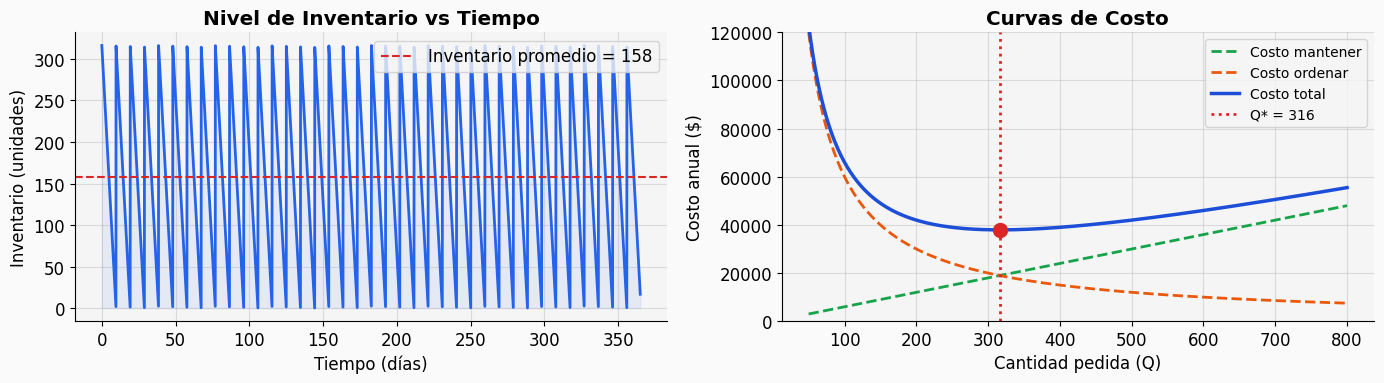

In [2]:
# ── Parámetros ──────────────────────────────────────────────────
D = 12_000        # demanda anual (unidades)
K = 500           # costo fijo por orden ($)
h = 10 * 12       # costo de mantener anual ($/unidad/año)  [mensual * 12]

# ── Cálculos EOQ ─────────────────────────────────────────────────
Q_star = np.sqrt(2 * K * D / h)
T_star = Q_star / D * 365          # tiempo entre pedidos (días)
N_star = D / Q_star                # número de pedidos por año
CT     = (K * D / Q_star) + (h * Q_star / 2)

print("=" * 45)
print(f"  Cantidad óptima Q*    : {Q_star:>8.2f}  unidades")
print(f"  Tiempo entre pedidos  : {T_star:>8.2f}  días")
print(f"  Pedidos por año N*    : {N_star:>8.1f}  pedidos")
print(f"  Costo total anual CT  : {CT:>9,.2f}  $")
print("=" * 45)

# ── Gráfico diente de sierra ─────────────────────────────────────
t = np.linspace(0, 365, 5000)
T_d = T_star
inv = Q_star * (1 - (t % T_d) / T_d)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Panel izquierdo: nivel de inventario
axes[0].plot(t, inv, color='#2563EB', lw=2)
axes[0].axhline(Q_star/2, color='#DC2626', linestyle='--', lw=1.5, label=f'Inventario promedio = {Q_star/2:.0f}')
axes[0].fill_between(t, inv, alpha=0.08, color='#2563EB')
axes[0].set_title('Nivel de Inventario vs Tiempo', fontweight='bold')
axes[0].set_xlabel('Tiempo (días)')
axes[0].set_ylabel('Inventario (unidades)')
axes[0].legend()

# Panel derecho: curvas de costo
Q_range = np.linspace(50, 800, 500)
CT_hold = h * Q_range / 2
CT_ord  = K * D / Q_range
CT_tot  = CT_hold + CT_ord

axes[1].plot(Q_range, CT_hold, '--', color='#16A34A', lw=2, label='Costo mantener')
axes[1].plot(Q_range, CT_ord,  '--', color='#EA580C', lw=2, label='Costo ordenar')
axes[1].plot(Q_range, CT_tot,  '-',  color='#1D4ED8', lw=2.5, label='Costo total')
axes[1].axvline(Q_star, color='#DC2626', linestyle=':', lw=2, label=f'Q* = {Q_star:.0f}')
axes[1].scatter([Q_star], [CT], color='#DC2626', zorder=5, s=100)
axes[1].set_title('Curvas de Costo', fontweight='bold')
axes[1].set_xlabel('Cantidad pedida (Q)')
axes[1].set_ylabel('Costo anual ($)')
axes[1].legend(fontsize=10)
axes[1].set_ylim(0, 120_000)

plt.tight_layout()
plt.show()


---
## 2. Punto de Reorden (con Lead Time)

Cuando existe un **tiempo de entrega** L (en días), el pedido debe hacerse antes de que se agote el stock:

$$R = D \cdot L$$

donde $D$ es la demanda diaria. El inventario baja hasta $R$ y allí se dispara la orden.


  Demanda diaria        : 32.88  unidades/día
  Punto de reorden R    : 164.38  unidades
  (pedir cuando quedan 164 unidades en stock)


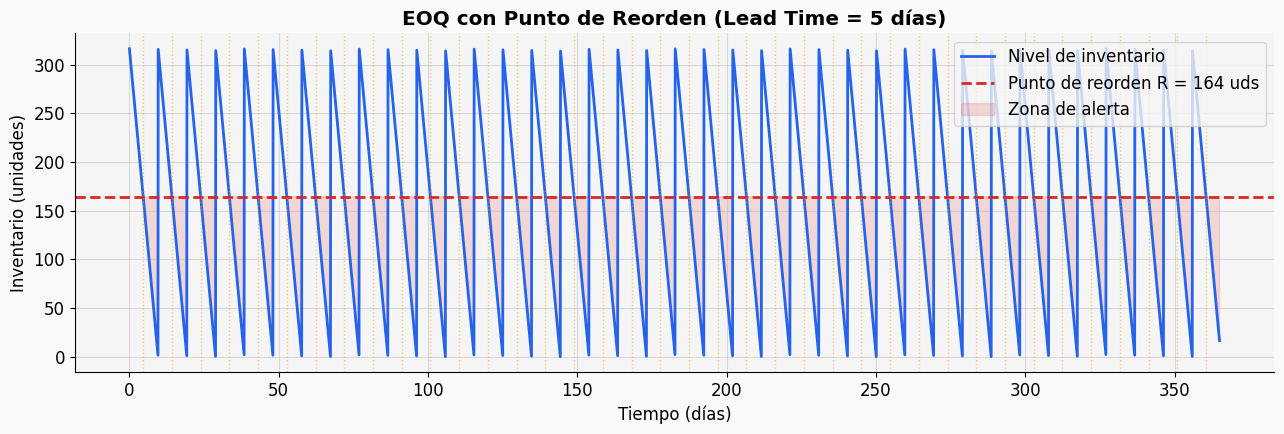

In [3]:
# ── Parámetros (continuamos con Thinkpad) ────────────────────────
L_dias = 5            # lead time en días

D_diario = D / 365
R = D_diario * L_dias

print(f"  Demanda diaria        : {D_diario:.2f}  unidades/día")
print(f"  Punto de reorden R    : {R:.2f}  unidades")
print(f"  (pedir cuando quedan {R:.0f} unidades en stock)")

# ── Gráfico ──────────────────────────────────────────────────────
t = np.linspace(0, 365, 5000)
inv = Q_star * (1 - (t % T_star) / T_star)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(t, inv, color='#2563EB', lw=2, label='Nivel de inventario')
ax.axhline(R, color='#DC2626', linestyle='--', lw=2, label=f'Punto de reorden R = {R:.0f} uds')

# Marcar momentos de reorden
for t0 in np.arange(0, 365, T_star):
    t_reorder = t0 + (T_star - L_dias)
    if t_reorder < 365:
        ax.axvline(t_reorder, color='#F59E0B', alpha=0.5, lw=1, linestyle=':')

ax.fill_between(t, R, inv, where=(inv <= R), alpha=0.15, color='#DC2626', label='Zona de alerta')
ax.set_title('EOQ con Punto de Reorden (Lead Time = 5 días)', fontweight='bold')
ax.set_xlabel('Tiempo (días)')
ax.set_ylabel('Inventario (unidades)')
ax.legend()
plt.tight_layout()
plt.show()


---
## 3. EOQ con Faltantes Permitidos (Backorders)

Si los clientes **esperan** cuando hay faltante, se puede optimizar permitiendo cierta escasez:

$$Q^* = \sqrt{\frac{2KD}{h}} \cdot \sqrt{\frac{p+h}{p}}, \quad S^* = Q^* \cdot \frac{p}{p+h}$$

donde $p$ = costo por unidad en backorder por año, y $S$ = inventario máximo al inicio del ciclo.

El **faltante máximo** es $B = Q^* - S^*$.


  Cantidad óptima Q*      :   336.65  unidades
  Inventario inicial S*   :   297.04  unidades
  Faltante máximo B*      :    39.61  unidades
  Tiempo total ciclo      :    10.24  días
    → con inventario      :     9.04  días
    → con faltante        :     1.20  días
  Costo total anual CT    : 35,645.31  $
  (vs EOQ sin faltantes   : 37,947.33  $)
  Ahorro                  :  2,302.02  $


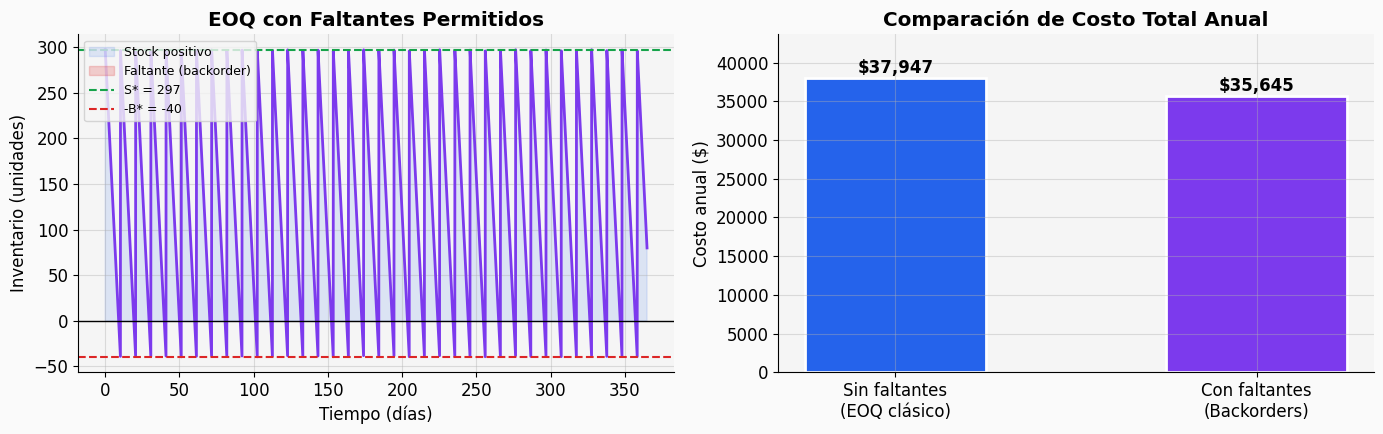

In [4]:
# ── Parámetros ──────────────────────────────────────────────────
p = 900           # costo por unidad no atendida ($)

# ── Cálculos ─────────────────────────────────────────────────────
Q_b  = np.sqrt(2*D*K/h) * np.sqrt((p + h)/p)
S_b  = Q_b * p / (p + h)
B_b  = Q_b - S_b
T_b  = Q_b / D * 365          # días entre pedidos
t1   = S_b / D * 365          # días con inventario positivo
t2   = B_b / D * 365          # días con faltante

CT_b = (K*D/Q_b) + (h * S_b**2)/(2*Q_b) + (p * B_b**2)/(2*Q_b)

print("=" * 50)
print(f"  Cantidad óptima Q*      : {Q_b:>8.2f}  unidades")
print(f"  Inventario inicial S*   : {S_b:>8.2f}  unidades")
print(f"  Faltante máximo B*      : {B_b:>8.2f}  unidades")
print(f"  Tiempo total ciclo      : {T_b:>8.2f}  días")
print(f"    → con inventario      : {t1:>8.2f}  días")
print(f"    → con faltante        : {t2:>8.2f}  días")
print(f"  Costo total anual CT    : {CT_b:>9,.2f}  $")
print(f"  (vs EOQ sin faltantes   : {CT:>9,.2f}  $)")
print(f"  Ahorro                  : {CT - CT_b:>9,.2f}  $")
print("=" * 50)

# ── Gráfico ──────────────────────────────────────────────────────
t_arr = np.linspace(0, 365, 8000)
T_dias = T_b
inv_b = np.zeros_like(t_arr)
for i, ti in enumerate(t_arr):
    t_mod = ti % T_dias
    if t_mod <= t1:
        inv_b[i] = S_b - D/365 * t_mod
    else:
        inv_b[i] = -D/365 * (t_mod - t1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(t_arr, inv_b, color='#7C3AED', lw=2)
axes[0].fill_between(t_arr, inv_b, 0, where=(inv_b >= 0), alpha=0.12, color='#2563EB', label='Stock positivo')
axes[0].fill_between(t_arr, inv_b, 0, where=(inv_b < 0),  alpha=0.20, color='#DC2626', label='Faltante (backorder)')
axes[0].axhline(0, color='black', lw=1)
axes[0].axhline(S_b, color='#16A34A', linestyle='--', lw=1.5, label=f'S* = {S_b:.0f}')
axes[0].axhline(-B_b, color='#DC2626', linestyle='--', lw=1.5, label=f'-B* = {-B_b:.0f}')
axes[0].set_title('EOQ con Faltantes Permitidos', fontweight='bold')
axes[0].set_xlabel('Tiempo (días)')
axes[0].set_ylabel('Inventario (unidades)')
axes[0].legend(fontsize=9)

# Comparación de costos
labels = ['Sin faltantes\n(EOQ clásico)', 'Con faltantes\n(Backorders)']
costos = [CT, CT_b]
colors = ['#2563EB', '#7C3AED']
bars = axes[1].bar(labels, costos, color=colors, width=0.5, edgecolor='white', linewidth=2)
for bar, v in zip(bars, costos):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 200, f'${v:,.0f}',
                 ha='center', va='bottom', fontweight='bold')
axes[1].set_title('Comparación de Costo Total Anual', fontweight='bold')
axes[1].set_ylabel('Costo anual ($)')
axes[1].set_ylim(0, max(costos) * 1.15)
plt.tight_layout()
plt.show()


---
## 4. Descuentos por Cantidad

Cuando el proveedor ofrece distintos precios según el volumen comprado, hay que evaluar cada tramo:

1. Calcular EOQ para cada precio (con $h = \alpha \cdot p$)
2. Si el EOQ cae dentro del rango válido → usar ese Q
3. Si el EOQ es menor al mínimo del tramo → usar el mínimo del tramo
4. Calcular $CT = \frac{KD}{Q} + \frac{hQ}{2} + D \cdot p$ para cada opción válida
5. Elegir el **menor CT**


     Tramo    Precio       EOQ   Q usado              CT
------------------------------------------------------------
     0-999  $    100     316.2     316.2  $   506,324.56
 1000-4999  $     95     324.4    1000.0  $   485,500.00
    5000-∞  $     90     333.3    5000.0  $   495,200.00
------------------------------------------------------------

 Política óptima: precio=$95, Q=1000 uds, CT=$485,500.00/año


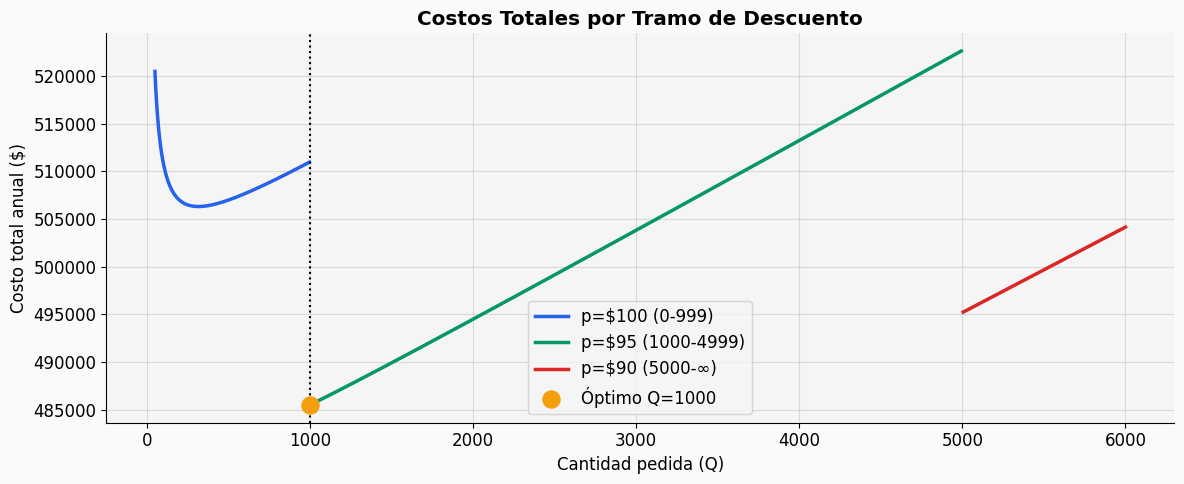

In [14]:
# ── Parámetros ──────────────────────────────────────────────────
D_d = 5_000
K_d = 200
alpha = 0.20      # h = 20% del precio unitario

tramos = [
    (0,    999,  100),   # (Q_min, Q_max, precio)
    (1000, 4999,  95),
    (5000, None,  90),
]

# ── Evaluación ───────────────────────────────────────────────────
resultados = []
print(f"{'Tramo':>10}  {'Precio':>8}  {'EOQ':>8}  {'Q usado':>8}  {'CT':>14}")
print("-" * 60)

for Q_min, Q_max, precio in tramos:
    h_d = alpha * precio
    EOQ = np.sqrt(2 * D_d * K_d / h_d)

    if Q_max is None:
        en_rango = EOQ >= Q_min
    else:
        en_rango = Q_min <= EOQ <= Q_max

    Q_eval = EOQ if en_rango else Q_min
    CT_d = (K_d * D_d / Q_eval) + (h_d * Q_eval / 2) + D_d * precio

    rango_str = f"{Q_min}-{Q_max if Q_max else '∞'}"
    print(f"{rango_str:>10}  ${precio:>7}  {EOQ:>8.1f}  {Q_eval:>8.1f}  ${CT_d:>13,.2f}")
    resultados.append((precio, Q_eval, CT_d, rango_str))

mejor = min(resultados, key=lambda x: x[2])
print("-" * 60)
print(f"\n Política óptima: precio=${mejor[0]}, Q={mejor[1]:.0f} uds, CT=${mejor[2]:,.2f}/año")

# ── Gráfico ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
colores = ['#2563EB', '#059669', '#DC2626']
Q_rng = np.linspace(50, 6000, 1000)

for (Q_min, Q_max, precio), color in zip(tramos, colores):
    h_d = alpha * precio
    CT_curva = (K_d * D_d / Q_rng) + (h_d * Q_rng / 2) + D_d * precio
    Q_lim = Q_max if Q_max else 6000
    mask = (Q_rng >= Q_min) & (Q_rng <= Q_lim)
    ax.plot(Q_rng[mask], CT_curva[mask], color=color, lw=2.5,
            label=f'p=${precio} ({Q_min}-{Q_max if Q_max else "∞"})')

# Marcar el óptimo
ax.axvline(mejor[1], color='black', linestyle=':', lw=1.5)
ax.scatter([mejor[1]], [mejor[2]], color='#F59E0B', zorder=10, s=150, label=f'Óptimo Q={mejor[1]:.0f}')
ax.set_title('Costos Totales por Tramo de Descuento', fontweight='bold')
ax.set_xlabel('Cantidad pedida (Q)')
ax.set_ylabel('Costo total anual ($)')
ax.legend()
plt.tight_layout()
plt.show()


---
## 5. Análisis de Sensibilidad

¿Qué tan robusto es el EOQ ante cambios en los parámetros?  
Exploramos cómo varía $Q^*$ y el costo total si los parámetros cambian ±50%.


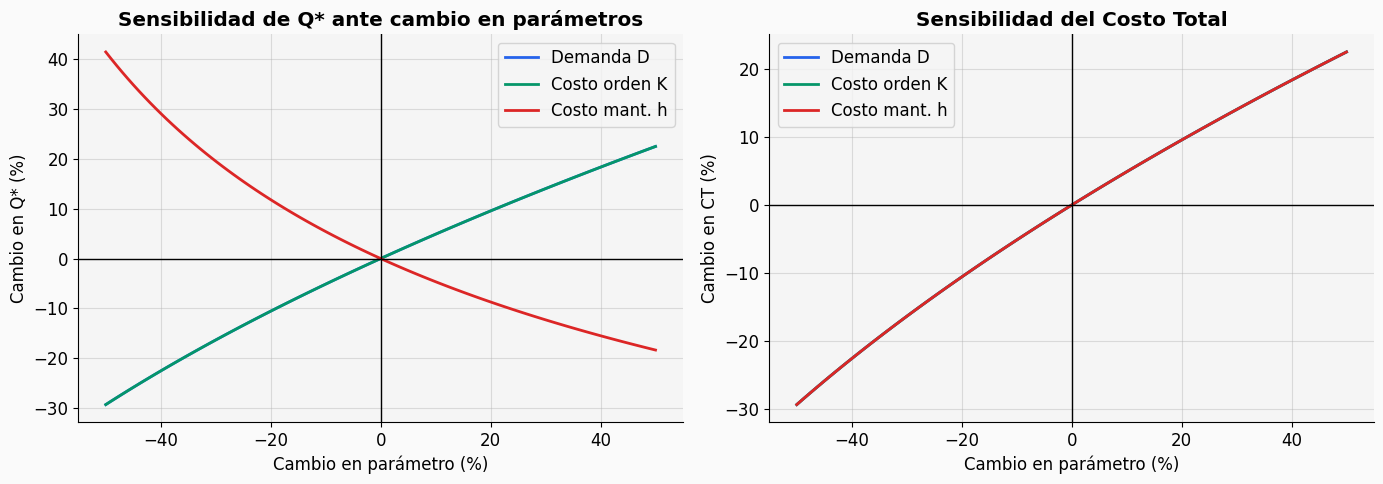

 Conclusión: El EOQ es poco sensible a errores en la estimación de parámetros.
   Un error del 20% en D solo mueve Q* ~10% → el modelo es robusto.


In [13]:
# ── Sensibilidad a D, K y h ──────────────────────────────────────
factores = np.linspace(0.5, 1.5, 100)

Q_vs_D  = np.sqrt(2 * K * (D * factores) / h)
Q_vs_K  = np.sqrt(2 * (K * factores) * D / h)
Q_vs_h  = np.sqrt(2 * K * D / (h * factores))

CT_vs_D = (K * (D*factores) / Q_vs_D) + (h * Q_vs_D / 2)
CT_vs_K = (K*factores * D / Q_vs_K) + (h * Q_vs_K / 2)
CT_vs_h = (K * D / Q_vs_h) + (h*factores * Q_vs_h / 2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cambio_pct = (factores - 1) * 100

for arr, label, col in [
    (Q_vs_D/Q_star - 1,   'Demanda D',     '#2563EB'),
    (Q_vs_K/Q_star - 1,   'Costo orden K', '#059669'),
    (Q_vs_h/Q_star - 1,   'Costo mant. h', '#DC2626'),
]:
    axes[0].plot(cambio_pct, arr*100, color=col, lw=2, label=label)

axes[0].axhline(0, color='black', lw=1)
axes[0].axvline(0, color='black', lw=1)
axes[0].set_title('Sensibilidad de Q* ante cambio en parámetros', fontweight='bold')
axes[0].set_xlabel('Cambio en parámetro (%)')
axes[0].set_ylabel('Cambio en Q* (%)')
axes[0].legend()

for arr, label, col in [
    (CT_vs_D/CT - 1,   'Demanda D',     '#2563EB'),
    (CT_vs_K/CT - 1,   'Costo orden K', '#059669'),
    (CT_vs_h/CT - 1,   'Costo mant. h', '#DC2626'),
]:
    axes[1].plot(cambio_pct, arr*100, color=col, lw=2, label=label)

axes[1].axhline(0, color='black', lw=1)
axes[1].axvline(0, color='black', lw=1)
axes[1].set_title('Sensibilidad del Costo Total', fontweight='bold')
axes[1].set_xlabel('Cambio en parámetro (%)')
axes[1].set_ylabel('Cambio en CT (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

print(" Conclusión: El EOQ es poco sensible a errores en la estimación de parámetros.")
print("   Un error del 20% en D solo mueve Q* ~10% → el modelo es robusto.")


---
## 6. Demanda Estocástica — Simulación Monte Carlo

En la realidad, $D$, $K$ y $h$ no son constantes. Con Monte Carlo podemos:
- Modelar la **distribución de $Q^*$** bajo incertidumbre
- Calcular intervalos de confianza para el costo total
- Estimar la probabilidad de faltantes dado un nivel de inventario

### 6.1 Distribuciones de entrada
| Parámetro | Distribución | Parámetros |
|-----------|-------------|-----------|
| Demanda anual $D$ | Normal | $\mu=12000$, $\sigma=1200$ |
| Costo de mantener $h$ | Uniforme | $[96, 144]$ (±20% de 120) |
| Lead time $L$ | Uniforme | $[3, 8]$ días |


In [7]:
np.random.seed(42)
n_sim = 50_000

# ── Sampleo de parámetros ─────────────────────────────────────────
D_sim = np.random.normal(loc=12_000, scale=1_200, size=n_sim).clip(1)
h_sim = np.random.uniform(0.80*120, 1.20*120, size=n_sim)
L_sim = np.random.uniform(3, 8, size=n_sim)   # lead time en días

# ── Cálculos vectorizados ─────────────────────────────────────────
Q_sim  = np.sqrt(2 * K * D_sim / h_sim)
CT_sim = (K * D_sim / Q_sim) + (h_sim * Q_sim / 2)
R_sim  = D_sim / 365 * L_sim

print(f"{'Métrica':25}  {'Media':>12}  {'P5':>10}  {'P95':>10}")
print("-" * 65)
for nombre, arr in [('EOQ Q* (uds)', Q_sim), ('Costo total CT ($)', CT_sim), ('Punto reorden R (uds)', R_sim)]:
    print(f"{nombre:25}  {arr.mean():>12,.1f}  {np.percentile(arr,5):>10,.1f}  {np.percentile(arr,95):>10,.1f}")


Métrica                           Media          P5         P95
-----------------------------------------------------------------
EOQ Q* (uds)                      317.5       279.2       359.7
Costo total CT ($)             37,831.8    33,146.0    42,595.5
Punto reorden R (uds)             181.0       104.4       266.2


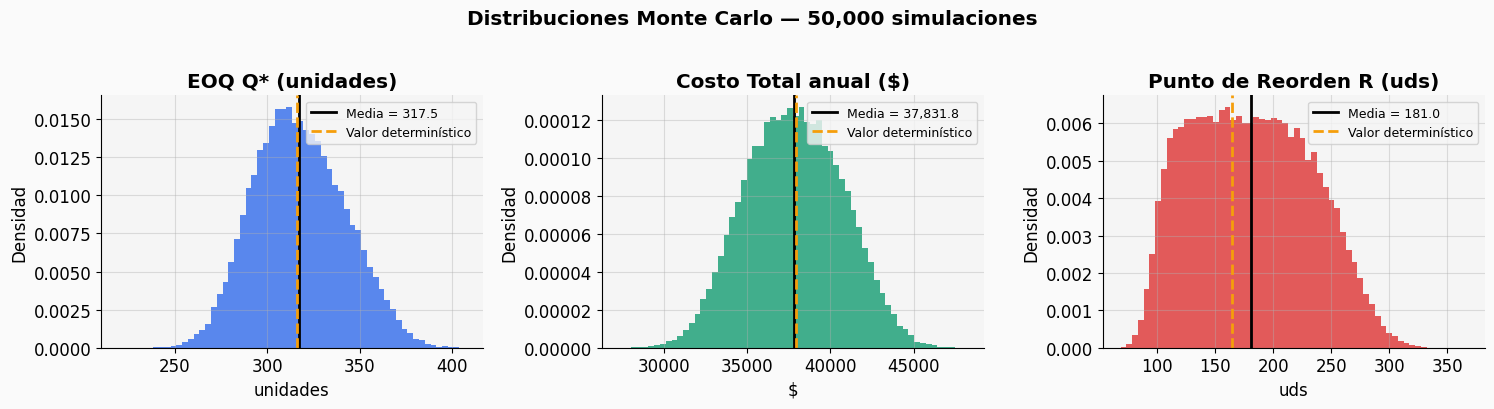

In [8]:
# ── Histogramas ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

datos = [
    (Q_sim,  'EOQ Q* (unidades)',      '#2563EB', Q_star),
    (CT_sim, 'Costo Total anual ($)',  '#059669', CT),
    (R_sim,  'Punto de Reorden R (uds)', '#DC2626', R),
]

for ax, (arr, titulo, color, det) in zip(axes, datos):
    ax.hist(arr, bins=60, color=color, alpha=0.75, edgecolor='none', density=True)
    ax.axvline(arr.mean(), color='black', lw=2, label=f'Media = {arr.mean():,.1f}')
    ax.axvline(det, color='#F59E0B', lw=2, linestyle='--', label=f'Valor determinístico')
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel(titulo.split('(')[-1].replace(')', ''))
    ax.set_ylabel('Densidad')
    ax.legend(fontsize=9)

plt.suptitle('Distribuciones Monte Carlo — 50,000 simulaciones', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 6.2 EOQ con Faltantes — Monte Carlo

Ahora con $p$ también aleatorio:


=== EOQ con Faltantes — Montecarlo ===
  Ahorro medio al permitir faltantes : $2,336.84/año
  % de simulaciones donde conviene   : 100.0%
  Faltante promedio máximo B*         :     40.0 unidades


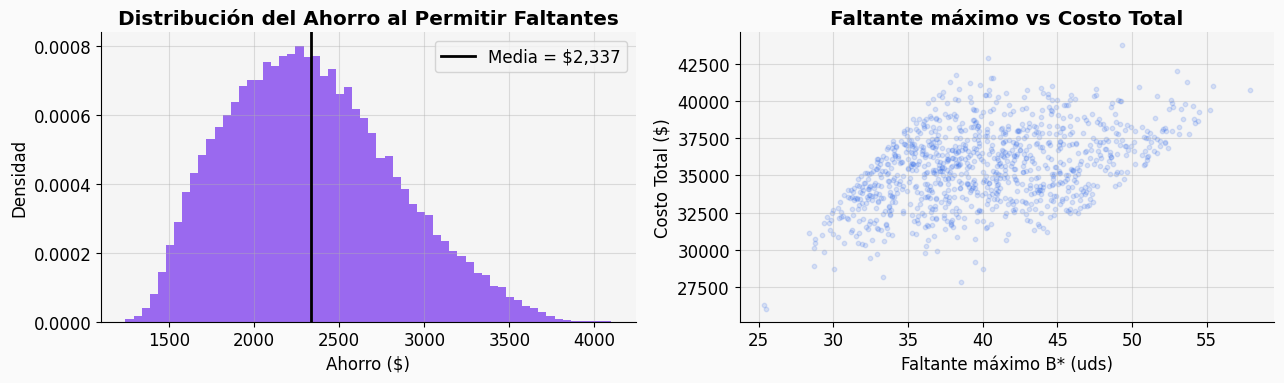

In [16]:
np.random.seed(123)
p_sim = np.random.uniform(700, 1100, size=n_sim)   # costo faltante variable

Q_f_sim = np.sqrt(2*D_sim*K/h_sim) * np.sqrt((p_sim + h_sim)/p_sim)
S_f_sim = Q_f_sim * p_sim / (p_sim + h_sim)
B_f_sim = Q_f_sim - S_f_sim
CT_f_sim = (K*D_sim/Q_f_sim) + (h_sim*S_f_sim**2)/(2*Q_f_sim) + (p_sim*B_f_sim**2)/(2*Q_f_sim)

ahorro_sim = CT_sim - CT_f_sim

print("=== EOQ con Faltantes — Montecarlo ===")
print(f"  Ahorro medio al permitir faltantes : ${ahorro_sim.mean():>8,.2f}/año")
print(f"  % de simulaciones donde conviene   : {(ahorro_sim > 0).mean()*100:.1f}%")
print(f"  Faltante promedio máximo B*         : {B_f_sim.mean():>8.1f} unidades")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(ahorro_sim, bins=60, color='#7C3AED', alpha=0.75, density=True)
axes[0].axvline(ahorro_sim.mean(), color='black', lw=2, label=f'Media = ${ahorro_sim.mean():,.0f}')
axes[0].set_title('Distribución del Ahorro al Permitir Faltantes', fontweight='bold')
axes[0].set_xlabel('Ahorro ($)')
axes[0].set_ylabel('Densidad')
axes[0].legend()

axes[1].scatter(B_f_sim[::50], CT_f_sim[::50], alpha=0.15, color='#2563EB', s=10)
axes[1].set_title('Faltante máximo vs Costo Total', fontweight='bold')
axes[1].set_xlabel('Faltante máximo B* (uds)')
axes[1].set_ylabel('Costo Total ($)')
plt.tight_layout()
plt.show()


### 6.3 Simulación Día a Día — Demanda Variable

Hasta ahora asumimos demanda constante. Ahora simulamos **día a día** con demanda aleatoria para ver cómo se comporta el inventario en la práctica.


  Stock de seguridad SS (95% NS)     : 30.2 unidades
  Punto de reorden con SS            : 194.6 unidades
  Faltantes — demanda determinística : 915.4
  Faltantes — demanda estocástica    : 1482.7
  Faltantes — con stock de seguridad : 173.5


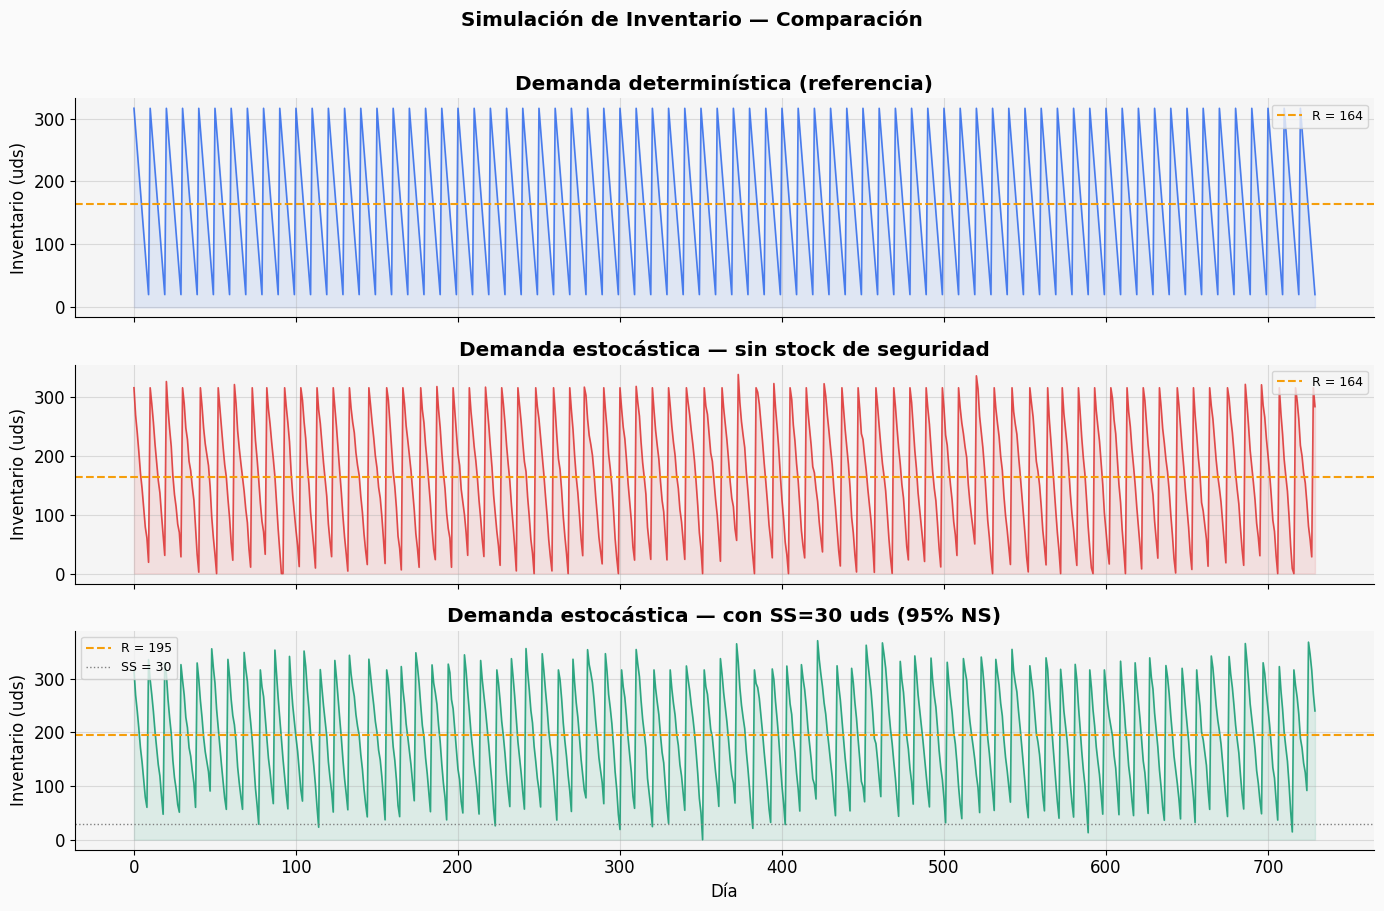

In [10]:
np.random.seed(7)

# ── Parámetros ──────────────────────────────────────────────────
D_diario_mu  = 12_000 / 365
D_diario_sig = D_diario_mu * 0.25    # CV = 25%
L_dias_det   = 5
dias_sim     = 730                    # 2 años

# ── Función de simulación ─────────────────────────────────────────
def simular_inventario(Q_pedido, R_reorden, dias, mu, sigma, lead_time, seed=None):
    if seed: np.random.seed(seed)
    inventario = np.zeros(dias + lead_time)
    inventario[0] = Q_pedido
    pedidos_en_camino = []  # (día de llegada)
    faltantes_total = 0

    for dia in range(dias):
        # ¿llegan pedidos hoy?
        llegados = [p for p in pedidos_en_camino if p == dia]
        inventario[dia] += Q_pedido * len(llegados)
        pedidos_en_camino = [p for p in pedidos_en_camino if p != dia]

        # Demanda del día
        dem = max(0, np.random.normal(mu, sigma))
        inventario[dia+1] = inventario[dia] - dem

        if inventario[dia+1] < 0:
            faltantes_total += abs(inventario[dia+1])
            inventario[dia+1] = 0

        # ¿hay que pedir?
        if inventario[dia+1] <= R_reorden and not pedidos_en_camino:
            pedidos_en_camino.append(dia + 1 + lead_time)

    return inventario[:dias], faltantes_total

inv_det, falt_det = simular_inventario(Q_star, R, dias_sim, D_diario_mu, 0, L_dias_det, seed=7)
inv_sto, falt_sto = simular_inventario(Q_star, R, dias_sim, D_diario_mu, D_diario_sig, L_dias_det, seed=7)

# Stock de seguridad
z = 1.645  # 95% nivel de servicio
SS = z * D_diario_sig * np.sqrt(L_dias_det)
R_sto = R + SS
inv_sto_ss, falt_sto_ss = simular_inventario(Q_star, R_sto, dias_sim, D_diario_mu, D_diario_sig, L_dias_det, seed=7)

print(f"  Stock de seguridad SS (95% NS)     : {SS:.1f} unidades")
print(f"  Punto de reorden con SS            : {R_sto:.1f} unidades")
print(f"  Faltantes — demanda determinística : {falt_det:.1f}")
print(f"  Faltantes — demanda estocástica    : {falt_sto:.1f}")
print(f"  Faltantes — con stock de seguridad : {falt_sto_ss:.1f}")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
t_dias = np.arange(dias_sim)

titulos = [
    ('Demanda determinística (referencia)', inv_det, '#2563EB', R, None),
    ('Demanda estocástica — sin stock de seguridad', inv_sto, '#DC2626', R, None),
    (f'Demanda estocástica — con SS={SS:.0f} uds (95% NS)', inv_sto_ss, '#059669', R_sto, SS),
]

for ax, (titulo, inv, color, reorder, ss) in zip(axes, titulos):
    ax.plot(t_dias, inv, color=color, lw=1.2, alpha=0.8)
    ax.fill_between(t_dias, inv, alpha=0.1, color=color)
    ax.axhline(reorder, color='#F59E0B', lw=1.5, linestyle='--', label=f'R = {reorder:.0f}')
    if ss:
        ax.axhline(ss, color='gray', lw=1, linestyle=':', label=f'SS = {ss:.0f}')
    ax.set_title(titulo, fontweight='bold')
    ax.set_ylabel('Inventario (uds)')
    ax.legend(fontsize=9)

axes[-1].set_xlabel('Día')
plt.suptitle('Simulación de Inventario — Comparación', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


---
## 7. Ejercicio Integrador + Análisis Completo

Usá las celdas de abajo para explorar el caso completo con todos los parámetros configurables.


In [11]:
# ╔══════════════════════════════════════════════════════════════╗
# ║         PARÁMETROS — modificá acá para explorar            ║
# ╚══════════════════════════════════════════════════════════════╝

D_ej   = 12_000     # Demanda anual (unidades)
K_ej   = 500        # Costo fijo por orden ($)
h_ej   = 120        # Costo de mantener anual ($/unidad)
p_ej   = 900        # Costo por faltante ($/unidad) — para el modelo con backorders
L_ej   = 5          # Lead time (días)
z_ej   = 1.645      # Factor de stock de seguridad (1.28=90%, 1.645=95%, 2.33=99%)
cv_ej  = 0.20       # Coeficiente de variación de la demanda diaria

# ─────────────────────────────────────────────────────────────
# Cálculos automáticos
# ─────────────────────────────────────────────────────────────
Q_ej  = np.sqrt(2*K_ej*D_ej/h_ej)
T_ej  = Q_ej/D_ej*365
N_ej  = D_ej/Q_ej
CT_ej = K_ej*D_ej/Q_ej + h_ej*Q_ej/2
R_ej  = D_ej/365*L_ej
sigma_d_ej = (D_ej/365)*cv_ej
SS_ej = z_ej * sigma_d_ej * np.sqrt(L_ej)
R_ss_ej = R_ej + SS_ej

Q_bf  = np.sqrt(2*D_ej*K_ej/h_ej) * np.sqrt((p_ej+h_ej)/p_ej)
S_bf  = Q_bf * p_ej/(p_ej+h_ej)
B_bf  = Q_bf - S_bf
CT_bf = K_ej*D_ej/Q_bf + h_ej*S_bf**2/(2*Q_bf) + p_ej*B_bf**2/(2*Q_bf)

print("┌─────────────────────────────────────────────────────┐")
print("│              RESUMEN DE RESULTADOS                  │")
print("├─────────────────────────────────────────────────────┤")
print("│  EOQ CLÁSICO (sin faltantes)                        │")
print(f"│    Q*           = {Q_ej:>8.2f}  unidades              │")
print(f"│    T*           = {T_ej:>8.2f}  días                  │")
print(f"│    N*           = {N_ej:>8.1f}  pedidos/año           │")
print(f"│    CT           = {CT_ej:>9,.2f}  $/año                │")
print("├─────────────────────────────────────────────────────┤")
print("│  PUNTO DE REORDEN                                   │")
print(f"│    R (det.)     = {R_ej:>8.2f}  unidades              │")
print(f"│    SS (95% NS)  = {SS_ej:>8.2f}  unidades              │")
print(f"│    R + SS       = {R_ss_ej:>8.2f}  unidades              │")
print("├─────────────────────────────────────────────────────┤")
print("│  EOQ CON FALTANTES                                  │")
print(f"│    Q*           = {Q_bf:>8.2f}  unidades              │")
print(f"│    S* (inv máx) = {S_bf:>8.2f}  unidades              │")
print(f"│    B* (falt máx)= {B_bf:>8.2f}  unidades              │")
print(f"│    CT           = {CT_bf:>9,.2f}  $/año                │")
print(f"│    Ahorro vs EOQ= {CT_ej-CT_bf:>9,.2f}  $                  │")
print("└─────────────────────────────────────────────────────┘")


┌─────────────────────────────────────────────────────┐
│              RESUMEN DE RESULTADOS                  │
├─────────────────────────────────────────────────────┤
│  EOQ CLÁSICO (sin faltantes)                        │
│    Q*           =   316.23  unidades              │
│    T*           =     9.62  días                  │
│    N*           =     37.9  pedidos/año           │
│    CT           = 37,947.33  $/año                │
├─────────────────────────────────────────────────────┤
│  PUNTO DE REORDEN                                   │
│    R (det.)     =   164.38  unidades              │
│    SS (95% NS)  =    24.19  unidades              │
│    R + SS       =   188.57  unidades              │
├─────────────────────────────────────────────────────┤
│  EOQ CON FALTANTES                                  │
│    Q*           =   336.65  unidades              │
│    S* (inv máx) =   297.04  unidades              │
│    B* (falt máx)=    39.61  unidades              │
│    CT     

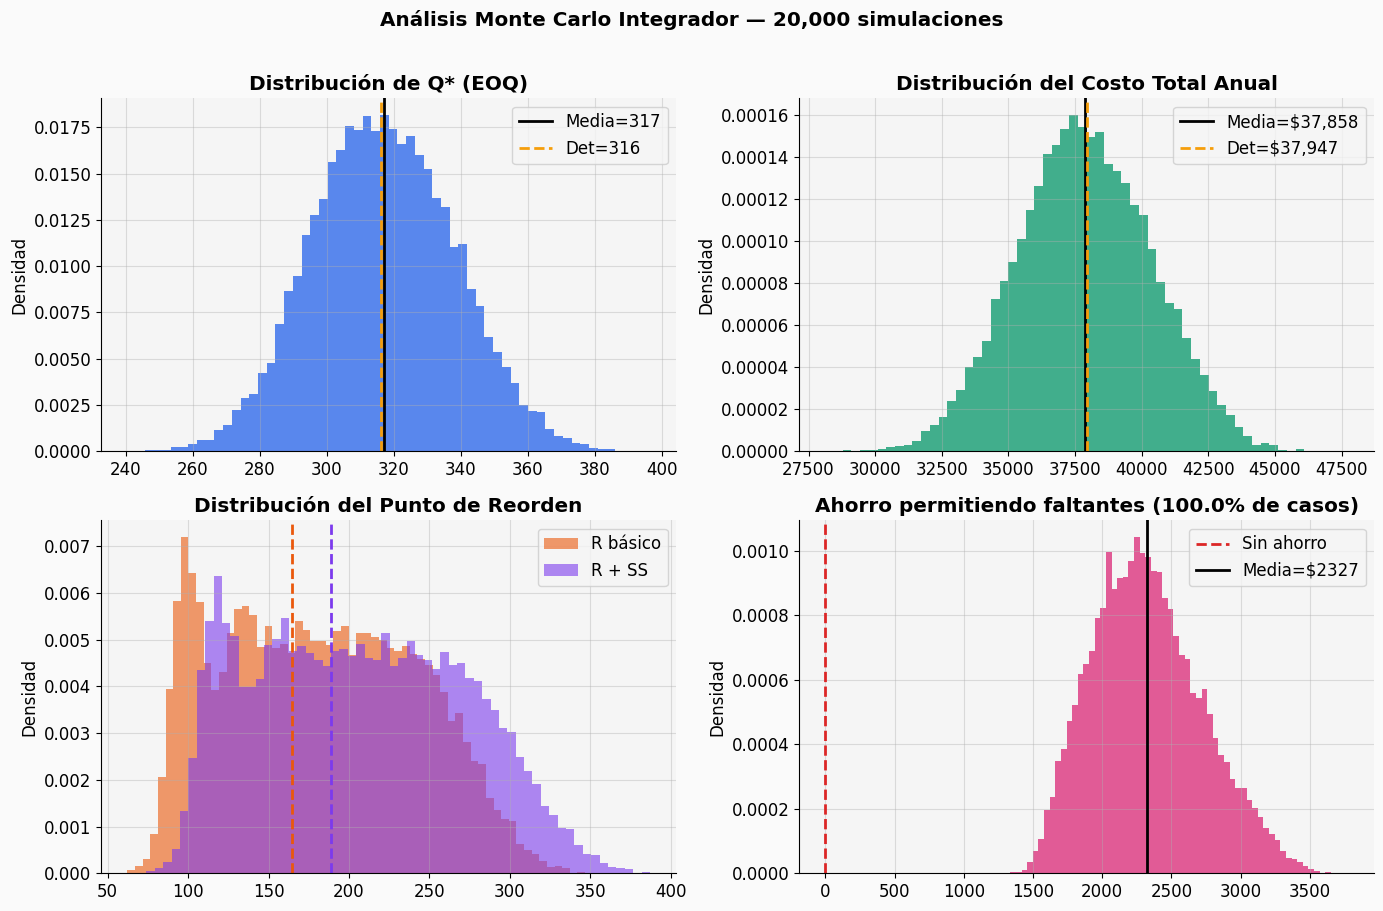


95% Intervalos de Confianza (Montecarlo):
  Q* (EOQ)       : [    276.7  ,      358.6]
  CT anual       : [ 33,007.3  ,   42,771.7]
  R + SS         : [    105.5  ,      326.5]


In [12]:
# ── Monte Carlo Integrador ────────────────────────────────────────
np.random.seed(42)
n_mc = 20_000

D_mc = np.random.normal(D_ej, D_ej*0.10, n_mc).clip(1)
h_mc = np.random.uniform(h_ej*0.85, h_ej*1.15, n_mc)
L_mc = np.random.randint(3, 9, n_mc).astype(float)
p_mc = np.random.uniform(p_ej*0.80, p_ej*1.20, n_mc)

Q_mc    = np.sqrt(2*K_ej*D_mc/h_mc)
CT_mc   = K_ej*D_mc/Q_mc + h_mc*Q_mc/2
R_mc    = D_mc/365 * L_mc
sig_mc  = (D_mc/365) * cv_ej
SS_mc   = z_ej * sig_mc * np.sqrt(L_mc)

Q_bf_mc = np.sqrt(2*D_mc*K_ej/h_mc) * np.sqrt((p_mc+h_mc)/p_mc)
S_bf_mc = Q_bf_mc * p_mc/(p_mc+h_mc)
B_bf_mc = Q_bf_mc - S_bf_mc
CT_bf_mc = K_ej*D_mc/Q_bf_mc + h_mc*S_bf_mc**2/(2*Q_bf_mc) + p_mc*B_bf_mc**2/(2*Q_bf_mc)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# EOQ
axes[0,0].hist(Q_mc, bins=60, color='#2563EB', alpha=0.75, density=True)
axes[0,0].axvline(Q_mc.mean(), color='black', lw=2, label=f'Media={Q_mc.mean():.0f}')
axes[0,0].axvline(Q_ej, color='#F59E0B', lw=2, ls='--', label=f'Det={Q_ej:.0f}')
axes[0,0].set_title('Distribución de Q* (EOQ)', fontweight='bold')
axes[0,0].legend()

# CT
axes[0,1].hist(CT_mc, bins=60, color='#059669', alpha=0.75, density=True)
axes[0,1].axvline(CT_mc.mean(), color='black', lw=2, label=f'Media=${CT_mc.mean():,.0f}')
axes[0,1].axvline(CT_ej, color='#F59E0B', lw=2, ls='--', label=f'Det=${CT_ej:,.0f}')
axes[0,1].set_title('Distribución del Costo Total Anual', fontweight='bold')
axes[0,1].legend()

# Punto de reorden + SS
axes[1,0].hist(R_mc, bins=60, color='#EA580C', alpha=0.6, density=True, label='R básico')
axes[1,0].hist(R_mc+SS_mc, bins=60, color='#7C3AED', alpha=0.6, density=True, label='R + SS')
axes[1,0].axvline(R_ej, color='#EA580C', lw=2, ls='--')
axes[1,0].axvline(R_ss_ej, color='#7C3AED', lw=2, ls='--')
axes[1,0].set_title('Distribución del Punto de Reorden', fontweight='bold')
axes[1,0].legend()

# Ahorro con backorders
ahorro_mc = CT_mc - CT_bf_mc
axes[1,1].hist(ahorro_mc, bins=60, color='#DB2777', alpha=0.75, density=True)
axes[1,1].axvline(0, color='#DC2626', lw=2, ls='--', label='Sin ahorro')
axes[1,1].axvline(ahorro_mc.mean(), color='black', lw=2, label=f'Media=${ahorro_mc.mean():.0f}')
pct = (ahorro_mc > 0).mean() * 100
axes[1,1].set_title(f'Ahorro permitiendo faltantes ({pct:.1f}% de casos)', fontweight='bold')
axes[1,1].legend()

for ax in axes.flat:
    ax.set_ylabel('Densidad')
plt.suptitle('Análisis Monte Carlo Integrador — 20,000 simulaciones', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# IC 95%
print("\n95% Intervalos de Confianza (Montecarlo):")
for nombre, arr in [('Q* (EOQ)', Q_mc), ('CT anual', CT_mc), ('R + SS', R_mc+SS_mc)]:
    lo, hi = np.percentile(arr, [2.5, 97.5])
    print(f"  {nombre:15}: [{lo:>9,.1f}  ,  {hi:>9,.1f}]")


---
## 8. Simulación Día a Día Completa — Optimización por Monte Carlo

En los modelos anteriores, los parámetros eran conocidos y constantes. En este ejercicio simulamos **365 días × N repeticiones** con:

- **Demanda diaria aleatoria** ~ Normal(μ, σ)
- **Lead time aleatorio** ~ Uniforme[L_min, L_max] días
- **Costo de mantener** por unidad por día en inventario
- **Costo de faltante** por unidad no atendida
- **Costo fijo por orden** cada vez que se hace un pedido

**Pregunta central:** dado un punto de reorden R fijo, ¿qué cantidad Q minimiza el costo total esperado?

La simulación evalúa una grilla de valores de Q y elige el óptimo empíricamente.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ╔══════════════════════════════════════════════════════════════╗
# ║              PARÁMETROS — modificá acá                      ║
# ╚══════════════════════════════════════════════════════════════╝

# Demanda diaria
D_mu     = 35       # demanda diaria promedio (unidades/día)
D_cv     = 0.20     # coeficiente de variación (0.20 = 20% de variabilidad)

# Lead time (días entre pedido y llegada)
L_min    = 3        # mínimo de días de entrega
L_max    = 7        # máximo de días de entrega

# Costos
c_orden   = 150     # costo fijo por orden emitida ($)
c_holding = 0.50    # costo de almacenar una unidad por día ($/unidad/día)
c_falta   = 8.00    # costo por unidad no atendida ($)

# Simulación
dias      = 365     # horizonte de simulación (días)
n_sim     = 500     # repeticiones Monte Carlo por cada Q
inv0      = 200     # inventario inicial

# Grilla de Q a evaluar
Q_grilla  = np.arange(50, 600, 25)

# Punto de reorden (R): cuántas unidades quedan cuando se dispara el pedido
# Una heurística de partida: demanda esperada durante el lead time promedio
L_prom    = (L_min + L_max) / 2
R         = int(D_mu * L_prom * 1.25)   # 25% de colchón sobre la demanda en tránsito

print(f"  Demanda diaria media  : {D_mu} uds/día  (σ = {D_mu*D_cv:.1f})")
print(f"  Lead time             : [{L_min}, {L_max}] días  (prom = {L_prom:.1f})")
print(f"  Punto de reorden R    : {R} unidades")
print(f"  Inventario inicial    : {inv0} unidades")
print(f"  Valores de Q a probar : {Q_grilla[0]} … {Q_grilla[-1]}  (paso 25)")
print(f"  Simulaciones por Q    : {n_sim}")

  Demanda diaria media  : 35 uds/día  (σ = 7.0)
  Lead time             : [3, 7] días  (prom = 5.0)
  Punto de reorden R    : 218 unidades
  Inventario inicial    : 200 unidades
  Valores de Q a probar : 50 … 575  (paso 25)
  Simulaciones por Q    : 500


In [18]:
def simular_un_año(Q, R, D_mu, D_cv, L_min, L_max,
                   c_orden, c_holding, c_falta, dias, inv0):
    """
    Simula un año de operación con demanda y lead time aleatorios.
    Devuelve el costo total del año.
    """
    inventario  = inv0
    pedido_llega = -1          # día en que llega el pedido en tránsito (-1 = ninguno)
    pedido_pendiente = False

    costo_holding = 0.0
    costo_faltante = 0.0
    costo_ordenes  = 0.0
    n_ordenes      = 0

    for dia in range(dias):

        # 1. ¿Llega un pedido hoy?
        if pedido_pendiente and dia == pedido_llega:
            inventario += Q
            pedido_pendiente = False

        # 2. Demanda del día
        demanda = max(0.0, np.random.normal(D_mu, D_mu * D_cv))

        # 3. Atender demanda
        atendido   = min(inventario, demanda)
        faltante   = demanda - atendido
        inventario -= atendido

        # 4. Acumular costos
        costo_holding  += c_holding * max(inventario, 0)
        costo_faltante += c_falta   * faltante

        # 5. ¿Hay que emitir un pedido?
        #    Condición: inventario ≤ R  y  no hay pedido en camino
        if inventario <= R and not pedido_pendiente:
            lead = int(np.random.uniform(L_min, L_max + 1))
            pedido_llega     = dia + lead
            pedido_pendiente = True
            costo_ordenes   += c_orden
            n_ordenes       += 1

    costo_total = costo_holding + costo_faltante + costo_ordenes
    return costo_total, costo_holding, costo_faltante, costo_ordenes, n_ordenes


# ── Barrido sobre la grilla de Q ─────────────────────────────────
np.random.seed(42)

resultados = {
    'Q':           [],
    'CT_medio':    [],
    'CT_std':      [],
    'hold_medio':  [],
    'falta_medio': [],
    'orden_medio': [],
    'n_ord_medio': [],
    'CT_p10':      [],
    'CT_p90':      [],
}

print("Corriendo simulaciones...\n")
print(f"{'Q':>6} | {'CT medio':>12} | {'Holding':>10} | {'Faltante':>10} | {'Órdenes':>10} | {'N ord':>7}")
print("-" * 65)

for Q_val in Q_grilla:
    cts, holds, falts, ords, nords = [], [], [], [], []
    for _ in range(n_sim):
        ct, h, f, o, n = simular_un_año(
            Q_val, R, D_mu, D_cv, L_min, L_max,
            c_orden, c_holding, c_falta, dias, inv0
        )
        cts.append(ct); holds.append(h); falts.append(f)
        ords.append(o); nords.append(n)

    resultados['Q'].append(Q_val)
    resultados['CT_medio'].append(np.mean(cts))
    resultados['CT_std'].append(np.std(cts))
    resultados['hold_medio'].append(np.mean(holds))
    resultados['falta_medio'].append(np.mean(falts))
    resultados['orden_medio'].append(np.mean(ords))
    resultados['n_ord_medio'].append(np.mean(nords))
    resultados['CT_p10'].append(np.percentile(cts, 10))
    resultados['CT_p90'].append(np.percentile(cts, 90))

    print(f"{Q_val:>6} | ${np.mean(cts):>11,.0f} | ${np.mean(holds):>9,.0f} | "
          f"${np.mean(falts):>9,.0f} | ${np.mean(ords):>9,.0f} | {np.mean(nords):>7.1f}")

# Convertir a arrays
for k in resultados:
    resultados[k] = np.array(resultados[k])

# Q óptimo = el que minimiza el CT medio
idx_opt = np.argmin(resultados['CT_medio'])
Q_opt   = resultados['Q'][idx_opt]
CT_opt  = resultados['CT_medio'][idx_opt]

print(f"\n{'═'*50}")
print(f"     Q óptimo (simulación)  : {Q_opt} unidades")
print(f"     Costo total esperado   : ${CT_opt:,.0f}/año")
print(f"     Holding esperado       : ${resultados['hold_medio'][idx_opt]:,.0f}/año")
print(f"     Costo faltantes        : ${resultados['falta_medio'][idx_opt]:,.0f}/año")
print(f"     Costo órdenes          : ${resultados['orden_medio'][idx_opt]:,.0f}/año")
print(f"     Número de órdenes      : {resultados['n_ord_medio'][idx_opt]:.1f}/año")
print(f"{'═'*50}")

# EOQ analítico de referencia (con demanda anual y h anual)
Q_analitico = np.sqrt(2 * c_orden * (D_mu * dias) / (c_holding * dias))
print(f"\n   EOQ analítico (referencia)  : {Q_analitico:.1f} unidades")
print(f"     (asume demanda y h constantes, sin faltantes)")

Corriendo simulaciones...

     Q |     CT medio |    Holding |   Faltante |    Órdenes |   N ord
-----------------------------------------------------------------
    50 | $     83,542 | $      811 | $   71,737 | $   10,994 |    73.3
    75 | $     70,130 | $    1,994 | $   57,103 | $   11,033 |    73.6
   100 | $     57,609 | $    3,920 | $   42,663 | $   11,025 |    73.5
   125 | $     46,695 | $    7,126 | $   28,574 | $   10,995 |    73.3
   150 | $     38,664 | $   12,735 | $   15,010 | $   10,918 |    72.8
   175 | $     36,148 | $   19,442 | $    6,384 | $   10,322 |    68.8
   200 | $     36,650 | $   24,492 | $    2,758 | $    9,400 |    62.7
   225 | $     38,126 | $   28,136 | $    1,512 | $    8,478 |    56.5
   250 | $     39,745 | $   30,826 | $    1,262 | $    7,657 |    51.0
   275 | $     41,166 | $   33,074 | $    1,115 | $    6,978 |    46.5
   300 | $     42,685 | $   35,216 | $    1,061 | $    6,407 |    42.7
   325 | $     44,397 | $   37,451 | $    1,024 | $    

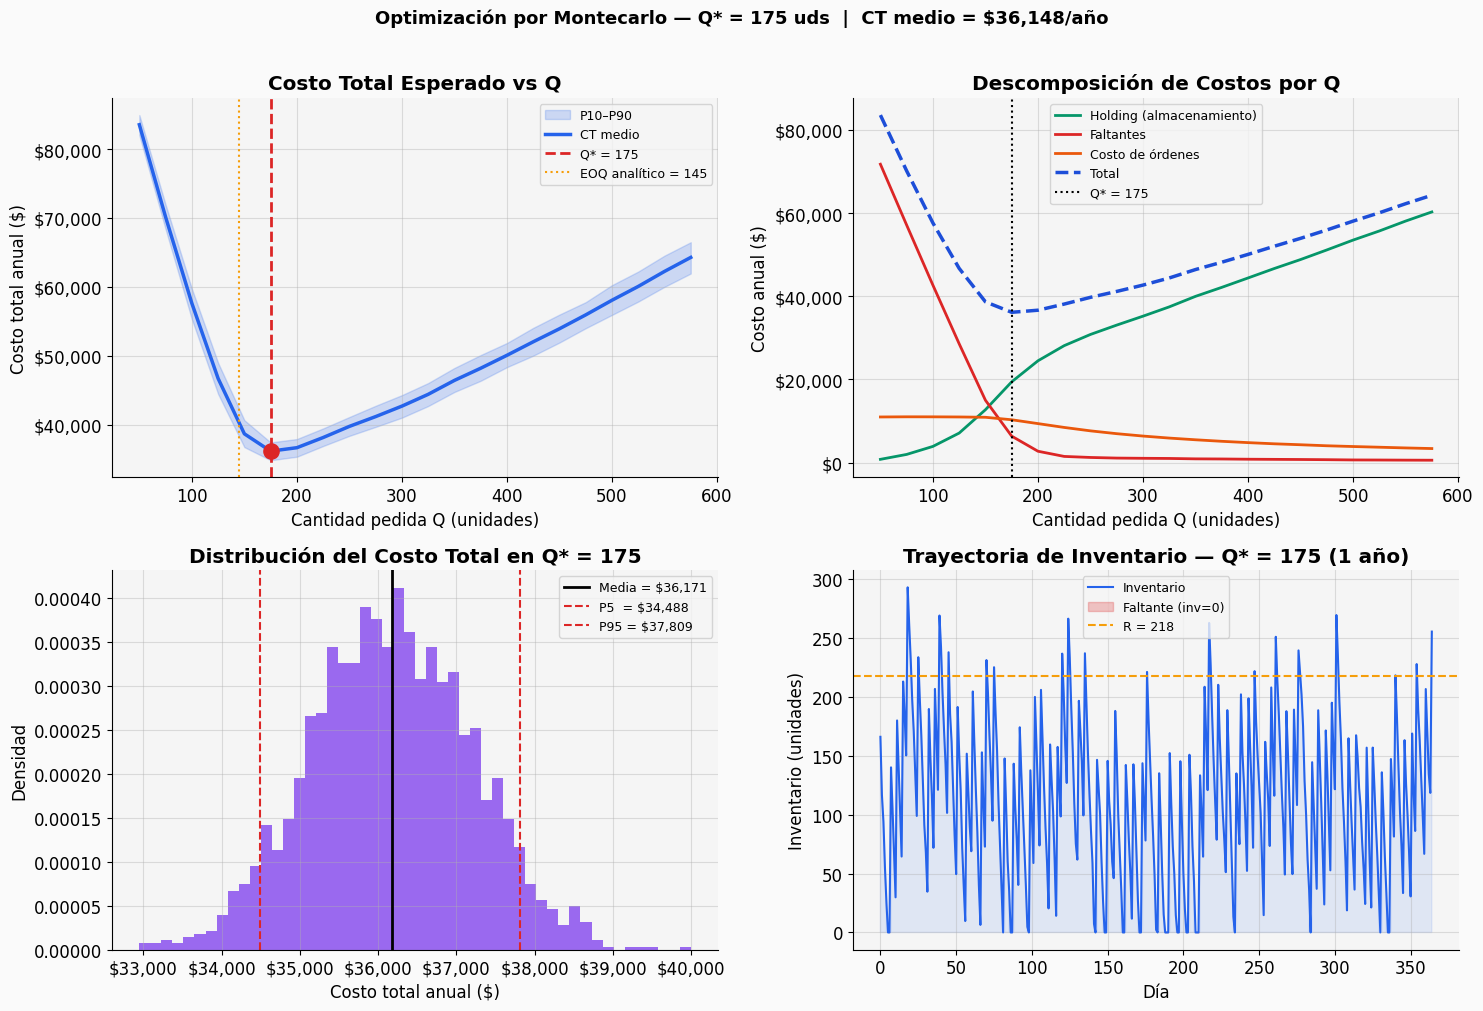

In [19]:
Q_arr      = resultados['Q']
CT_arr     = resultados['CT_medio']
hold_arr   = resultados['hold_medio']
falta_arr  = resultados['falta_medio']
orden_arr  = resultados['orden_medio']
p10_arr    = resultados['CT_p10']
p90_arr    = resultados['CT_p90']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# ── Panel 1: Costo total + banda de incertidumbre ────────────────
ax = axes[0, 0]
ax.fill_between(Q_arr, p10_arr, p90_arr, alpha=0.20, color='#2563EB', label='P10–P90')
ax.plot(Q_arr, CT_arr, color='#2563EB', lw=2.5, label='CT medio')
ax.axvline(Q_opt, color='#DC2626', lw=2, linestyle='--', label=f'Q* = {Q_opt}')
ax.axvline(Q_analitico, color='#F59E0B', lw=1.5, linestyle=':', label=f'EOQ analítico = {Q_analitico:.0f}')
ax.scatter([Q_opt], [CT_opt], color='#DC2626', s=120, zorder=10)
ax.set_title('Costo Total Esperado vs Q', fontweight='bold')
ax.set_xlabel('Cantidad pedida Q (unidades)')
ax.set_ylabel('Costo total anual ($)')
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# ── Panel 2: Descomposición de costos ────────────────────────────
ax = axes[0, 1]
ax.plot(Q_arr, hold_arr,  color='#059669', lw=2,   label='Holding (almacenamiento)')
ax.plot(Q_arr, falta_arr, color='#DC2626', lw=2,   label='Faltantes')
ax.plot(Q_arr, orden_arr, color='#EA580C', lw=2,   label='Costo de órdenes')
ax.plot(Q_arr, CT_arr,    color='#1D4ED8', lw=2.5, label='Total', linestyle='--')
ax.axvline(Q_opt, color='black', lw=1.5, linestyle=':', label=f'Q* = {Q_opt}')
ax.set_title('Descomposición de Costos por Q', fontweight='bold')
ax.set_xlabel('Cantidad pedida Q (unidades)')
ax.set_ylabel('Costo anual ($)')
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# ── Panel 3: Distribución del CT en Q* ───────────────────────────
ax = axes[1, 0]
np.random.seed(42)
cts_opt = [
    simular_un_año(Q_opt, R, D_mu, D_cv, L_min, L_max,
                   c_orden, c_holding, c_falta, dias, inv0)[0]
    for _ in range(2000)
]
ax.hist(cts_opt, bins=50, color='#7C3AED', alpha=0.75, density=True, edgecolor='none')
ax.axvline(np.mean(cts_opt), color='black', lw=2,
           label=f'Media = ${np.mean(cts_opt):,.0f}')
ax.axvline(np.percentile(cts_opt, 5),  color='#DC2626', lw=1.5, linestyle='--',
           label=f'P5  = ${np.percentile(cts_opt, 5):,.0f}')
ax.axvline(np.percentile(cts_opt, 95), color='#DC2626', lw=1.5, linestyle='--',
           label=f'P95 = ${np.percentile(cts_opts := np.array(cts_opt), 95):,.0f}')
ax.set_title(f'Distribución del Costo Total en Q* = {Q_opt}', fontweight='bold')
ax.set_xlabel('Costo total anual ($)')
ax.set_ylabel('Densidad')
ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# ── Panel 4: Trayectoria de inventario en Q* ─────────────────────
ax = axes[1, 1]
np.random.seed(99)
# Simular un año y guardar trayectoria
inventario_tray  = []
inv              = inv0
pedido_llega     = -1
pedido_pendiente = False

for dia in range(dias):
    if pedido_pendiente and dia == pedido_llega:
        inv += Q_opt
        pedido_pendiente = False
    demanda    = max(0.0, np.random.normal(D_mu, D_mu * D_cv))
    atendido   = min(inv, demanda)
    inv       -= atendido
    inventario_tray.append(inv)
    if inv <= R and not pedido_pendiente:
        lead             = int(np.random.uniform(L_min, L_max + 1))
        pedido_llega     = dia + lead
        pedido_pendiente = True

inv_tray = np.array(inventario_tray)
ax.plot(inv_tray, color='#2563EB', lw=1.5, label='Inventario')
ax.fill_between(range(dias), inv_tray, 0, where=(inv_tray > 0), alpha=0.10, color='#2563EB')
ax.fill_between(range(dias), inv_tray, 0, where=(inv_tray == 0), alpha=0.25, color='#DC2626',
                label='Faltante (inv=0)')
ax.axhline(R, color='#F59E0B', lw=1.5, linestyle='--', label=f'R = {R}')
ax.set_title(f'Trayectoria de Inventario — Q* = {Q_opt} (1 año)', fontweight='bold')
ax.set_xlabel('Día')
ax.set_ylabel('Inventario (unidades)')
ax.legend(fontsize=9)

plt.suptitle(
    f'Optimización por Montecarlo — Q* = {Q_opt} uds  |  CT medio = ${CT_opt:,.0f}/año',
    fontweight='bold', fontsize=13, y=1.01
)
plt.tight_layout()
plt.show()

Sensibilidad del Q* y CT óptimo al punto de reorden R:

     R |   Q* óptimo |     CT medio
--------------------------------------
    84 |         275 | $     44,784
    94 |         250 | $     43,316
   104 |         250 | $     41,915
   114 |         250 | $     40,493
   124 |         225 | $     39,422
   134 |         200 | $     38,088
   144 |         200 | $     37,254
   154 |         175 | $     36,641
   164 |         200 | $     36,098
   174 |         200 | $     35,562
   184 |         200 | $     35,474
   194 |         200 | $     35,653
   204 |         175 | $     35,857
   214 |         175 | $     35,980
   224 |         175 | $     36,220
   234 |         175 | $     36,495
   244 |         175 | $     37,116
   254 |         175 | $     37,485
   264 |         175 | $     38,112
   274 |         175 | $     38,880
   284 |         150 | $     38,999
   294 |         150 | $     39,152
   304 |         150 | $     39,070
   314 |         150 | $     38,942
   32

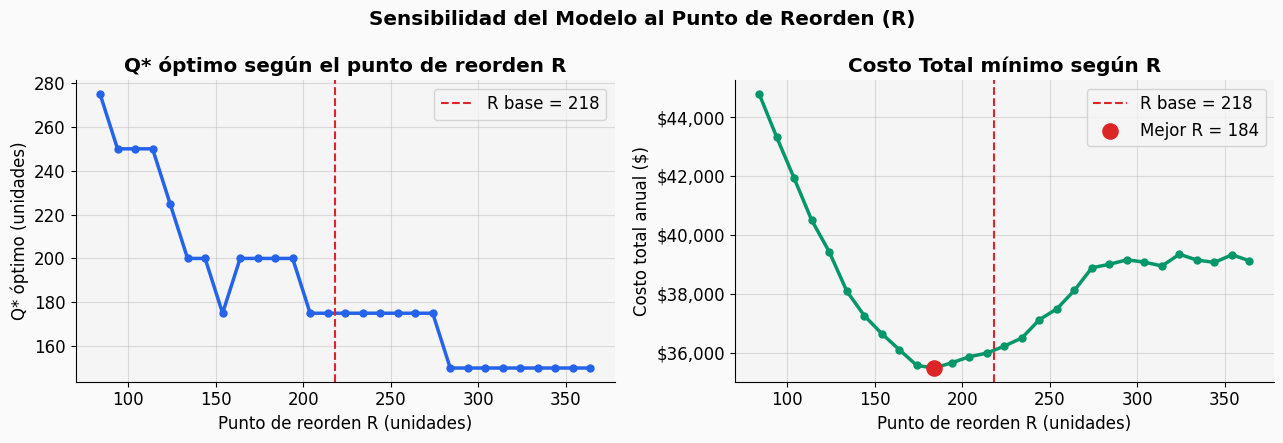


✅ R óptimo encontrado por simulación : 184 unidades
   CT mínimo asociado                 : $35,474/año


In [20]:
# ── ¿Cómo cambia el óptimo si variamos R? ─────────────────────────
R_vals   = np.arange(int(D_mu*L_min*0.8), int(D_mu*L_max*1.5), 10)
CT_por_R = []
Q_por_R  = []

np.random.seed(42)
print("Sensibilidad del Q* y CT óptimo al punto de reorden R:\n")
print(f"{'R':>6} | {'Q* óptimo':>11} | {'CT medio':>12}")
print("-" * 38)

for R_val in R_vals:
    cts_R = []
    for Q_val in Q_grilla:
        cts_q = [
            simular_un_año(Q_val, R_val, D_mu, D_cv, L_min, L_max,
                           c_orden, c_holding, c_falta, dias, inv0)[0]
            for _ in range(200)     # menos iteraciones para que sea rápido
        ]
        cts_R.append((Q_val, np.mean(cts_q)))
    mejor_R = min(cts_R, key=lambda x: x[1])
    Q_por_R.append(mejor_R[0])
    CT_por_R.append(mejor_R[1])
    print(f"{R_val:>6} | {mejor_R[0]:>11} | ${mejor_R[1]:>11,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(R_vals, Q_por_R, color='#2563EB', lw=2.5, marker='o', markersize=5)
axes[0].axvline(R, color='#DC2626', lw=1.5, linestyle='--', label=f'R base = {R}')
axes[0].set_title('Q* óptimo según el punto de reorden R', fontweight='bold')
axes[0].set_xlabel('Punto de reorden R (unidades)')
axes[0].set_ylabel('Q* óptimo (unidades)')
axes[0].legend()

axes[1].plot(R_vals, CT_por_R, color='#059669', lw=2.5, marker='o', markersize=5)
axes[1].axvline(R, color='#DC2626', lw=1.5, linestyle='--', label=f'R base = {R}')
idx_best_R = np.argmin(CT_por_R)
axes[1].scatter([R_vals[idx_best_R]], [CT_por_R[idx_best_R]],
                color='#DC2626', s=120, zorder=10,
                label=f'Mejor R = {R_vals[idx_best_R]}')
axes[1].set_title('Costo Total mínimo según R', fontweight='bold')
axes[1].set_xlabel('Punto de reorden R (unidades)')
axes[1].set_ylabel('Costo total anual ($)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].legend()

plt.suptitle('Sensibilidad del Modelo al Punto de Reorden (R)', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n R óptimo encontrado por simulación : {R_vals[idx_best_R]} unidades")
print(f"   CT mínimo asociado                 : ${CT_por_R[idx_best_R]:,.0f}/año")

---
## Resumen de Fórmulas

| Modelo | Fórmula | Observación |
|--------|---------|-------------|
| EOQ clásico | $Q^* = \sqrt{\frac{2KD}{h}}$ | Sin faltantes, sin lead time |
| Costo total | $CT = \frac{KD}{Q} + \frac{hQ}{2}$ | Se minimiza en $Q^*$ |
| Tiempo entre pedidos | $T^* = \frac{Q^*}{D}$ | En las mismas unidades que D |
| Punto de reorden | $R = D \cdot L$ | L en mismas unidades que D |
| Stock de seguridad | $SS = z \cdot \sigma_d \cdot \sqrt{L}$ | z según nivel de servicio |
| EOQ con faltantes | $Q^* = \sqrt{\frac{2KD}{h}} \cdot \sqrt{\frac{p+h}{p}}$ | $p$ = costo de backorder |
| Inventario máx (back.) | $S^* = Q^* \cdot \frac{p}{p+h}$ | |
